## Identify a plant and save it

Fits the catalog to a closed-loop P log by minimizing output error with lmfit, then writes `plant.json`. The fitted plant is a python-control `NonlinearIOSystem`: a transfer function with a Coulomb dead-zone on the input. P is the gain recorded in the log, `median(p_term / error)`, not a fitted parameter. This notebook does not tune a PID.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

import plantid

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent

LOG = ROOT / "data" / "fr_turn_pid_ground.csv"
OUT = ROOT / "plant.json"

time_stamp,time_s,set_point,measure_value,error,acc_error,out,dt_s,p_term,i_term,d_term
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1597446175,0.0,-0.0,-9.875488,9.875488,-0.0,9.875488,0.015,9.875488,-0.0,0.0
1600014172,0.015106,-0.0,-9.875488,9.875488,-0.0,9.875488,0.015106,9.875488,-0.0,0.0
1602601530,0.030326,-0.0,-9.875488,9.875488,-0.0,9.875488,0.01522,9.875488,-0.0,0.0
1605169887,0.0454336,-0.0,-9.875488,9.875488,-0.0,9.875488,0.015108,9.875488,-0.0,0.0
1607738966,0.060546,-0.0,-9.875488,9.875488,-0.0,9.875488,0.015112,9.875488,-0.0,0.0


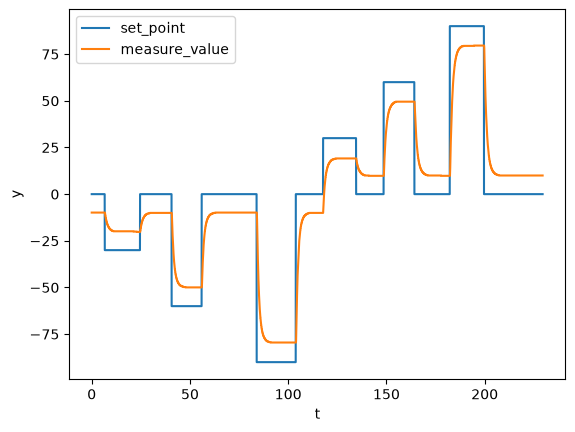

In [6]:
turn = pl.read_csv(LOG).sort("time_s")
t = turn["time_s"].to_numpy()
r = turn["set_point"].to_numpy()
y = turn["measure_value"].to_numpy()

_, ax = plt.subplots()
ax.plot(t, r, label="set_point")
ax.plot(t, y, label="measure_value")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.legend()
turn.head()

In [7]:
Kp = plantid.loop_gain(turn["error"].to_numpy(), turn["p_term"].to_numpy())
print(f"P recorded in the log: {Kp:g}")

found = plantid.search(t, r, y, plantid.default_models(), kp=Kp)
best = found.best
plantid.save(
    best.plant,
    OUT,
    model=best.model.name,
    kp=best.kp,
    rmse=best.rmse,
    formula=best.formula(),
)
print(best.model.name)
print(f"P = {best.kp:g}")
print(f"G(s) = {best.formula()}")
print(f"Fc = {best.plant.params['fc']:.4g}   RMSE = {best.rmse:.4g}")
print(f"saved {OUT}")
found.table

P recorded in the log: 1
inercyjny 3 + tarcie
P = 1
G(s) = 321.2 / (427 s + 1)(0.06892 s + 1)(0.06889 s + 1)
Fc = 10.16   RMSE = 0.5047
saved /home/mateuszzx/Workspace/Kalman_Workspace/PID/plant.json


model,P,G(s),Fc,rmse,at_bound
str,f64,str,f64,f64,bool
"""inercyjny 3 + tarcie""",1.0,"""321.2 / (427 s + 1)(0.06892 s …",10.160935,0.504682,false
"""inercyjny 2 + tarcie""",1.0,"""319 / (423.2 s + 1)(0.1361 s +…",10.159363,0.517256,false
"""całkujący, inercja 2 + tarcie""",1.0,"""0.7504 / (s (0.06783 s + 1)(0.…",10.149869,0.532249,false
"""całkujący, inercja 1 + tarcie""",1.0,"""0.7519 / (s (0.1335 s + 1))""",10.147072,0.544652,false
"""inercyjny 1 + tarcie""",1.0,"""394 / (531.3 s + 1)""",9.965277,0.827163,false
"""całkujący + tarcie""",1.0,"""0.7407 / s""",9.968448,0.837262,false
"""inercyjny 1""",1.0,"""7.341 / (14.61 s + 1)""",null,7.227842,false
"""inercyjny 2""",1.0,"""7.339 / (14.61 s + 1)(0.000911…",null,7.228518,true
"""inercyjny 3""",1.0,"""7.336 / (14.6 s + 1)(0.0009119…",null,7.229197,true


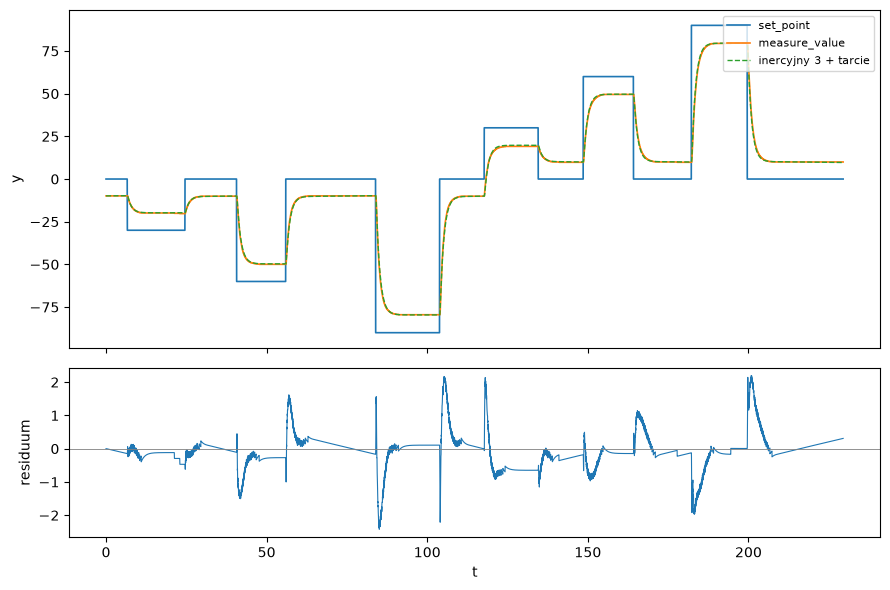

In [8]:
fig, axes = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": (2, 1)}
)
axes[0].plot(t, r, label="set_point", lw=1.2)
axes[0].plot(t, y, label="measure_value", lw=1.2)
axes[0].plot(t, best.prediction, ls="--", label=best.model.name, lw=1.0)
axes[0].set_ylabel("y")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t, y - best.prediction, lw=0.8)
axes[1].axhline(0.0, color="0.5", lw=0.6)
axes[1].set_xlabel("t")
axes[1].set_ylabel("residuum")
fig.tight_layout()